In [232]:
import planetary_computer
import pystac_client
from IPython.display import display, Markdown

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)
collection = catalog.get_collection("sentinel-3-slstr-lst-l2-netcdf")

display(Markdown(f"### {collection.id}\n\n{collection.description}"))

### sentinel-3-slstr-lst-l2-netcdf

This Collection provides Sentinel-3 [SLSTR Level-2 Land Surface Temperature](https://sentinel.esa.int/web/sentinel/user-guides/sentinel-3-slstr/product-types/level-2-lst) products containing data on land surface temperature measurements on a 1km grid. Radiance is measured in two channels to determine the temperature of the Earth's surface skin in the instrument field of view, where the term "skin" refers to the top surface of bare soil or the effective emitting temperature of vegetation canopies as viewed from above.

## Data files

The dataset includes data on the primary measurement variable, land surface temperature, in a single NetCDF file, `LST_in.nc`. A second file, `LST_ancillary.nc`, contains several ancillary variables:

- Normalized Difference Vegetation Index
- Surface biome classification
- Fractional vegetation cover
- Total water vapor column

In addition to the primary and ancillary data files, a standard set of annotation data files provide meteorological information, geolocation and time coordinates, geometry information, and quality flags. More information about the product and data processing can be found in the [User Guide](https://sentinels.copernicus.eu/web/sentinel/user-guides/sentinel-3-slstr/product-types/level-2-lst) and [Technical Guide](https://sentinel.esa.int/web/sentinel/technical-guides/sentinel-3-slstr/level-2/lst-processing).

This Collection contains Level-2 data in NetCDF files from April 2016 to present.

## STAC Item geometries

The Collection contains small "chips" and long "stripes" of data collected along the satellite direction of travel. Approximately five percent of the STAC Items describing long stripes of data contain geometries that encompass a larger area than an exact concave hull of the data extents. This may require additional filtering when searching the Collection for Items that spatially intersect an area of interest.


In [233]:
bbox = [-74.01, 40.75, -73.86, 40.88]
time_window = "2021-06-01/2021-09-01"

In [234]:
import xarray as xr
import fsspec

search = catalog.search(
    bbox=bbox, 
    datetime=time_window,
    collections=["sentinel-3-slstr-lst-l2-netcdf"],
    query={"eo:cloud_cover": {"lt": 30}},
)

items = list(search.get_items())
print('This is the number of scenes that touch our region:',len(items))


This is the number of scenes that touch our region: 21


C:\Users\16539\AppData\Roaming\Python\Python310\site-packages\pystac_client\item_search.py:826: FutureWarning: get_items() is deprecated, use items() instead
  warnings.warn(


In [235]:
import rich.table

item = next(search.items())

t = rich.table.Table("Key", "Value")
for key, asset in item.assets.items():
    t.add_row(key, asset.description)

t

┏━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Key                ┃ Value                                                                         ┃
┡━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ lst-in             │ Land Surface Temperature (LST) values                                         │
│ slstr-met-tx       │ Meteorological parameters regridded onto the 16km tie points                  │
│ safe-manifest      │ SAFE product manifest                                                         │
│ slstr-time-in      │ Time annotations for the 1km grid                                             │
│ slstr-flags-in     │ Global flags for the 1km TIR grid, nadir view                                 │
│ lst-ancillary-ds   │ LST ancillary measurement dataset                                             │
│ slstr-indices-in   │ Scan, pixel and detector indices annotations for the 1km TIR grid, nadir view │
│ slstr-geodetic-in  │ Full resolution geodetic coordinates for the 1km TIR grid, nadir view         │
│ slstr-geodetic-tx  │ 16km geodetic coordinates                                                     │
│ slstr-geometry-tn  │ 16km solar and satellite geometry annotations, nadir view                     │
│ slstr-cartesian-in │ Full resolution cartesian coordinates for the 1km TIR grid, nadir view        │
│ slstr-cartesian-tx │ 16km cartesian coordinates                                                    │
└────────────────────┴───────────────────────────────────────────────────────────────────────────────┘

In [236]:
dataset = xr.open_dataset(fsspec.open(item.assets["lst-in"].href).open())
dataset

<xarray.Dataset>
Dimensions:                 (rows: 1200, columns: 1500, orphan_pixels: 187)
Dimensions without coordinates: rows, columns, orphan_pixels
Data variables:
    LST                     (rows, columns) float32 ...
    LST_orphan              (rows, orphan_pixels) float32 ...
    LST_uncertainty         (rows, columns) float32 ...
    LST_uncertainty_orphan  (rows, orphan_pixels) float32 ...
    exception               (rows, columns) int16 ...
    exception_orphan        (rows, orphan_pixels) int16 ...
Attributes: (12/16)
    absolute_orbit_number:  17380
    comment:                 
    contact:                eosupport@copernicus.esa.int
    creation_time:          20210828T012330Z
    history:                  2021-08-28T01:23:30Z: PUGCoreProcessor /data/ip...
    institution:            LN2
    ...                     ...
    source:                 IPF-SL-2 06.18
    start_offset:           54882
    start_time:             2021-08-26T15:40:26.116731Z
    stop_time:              2021-08-26T15:43:25.810293Z
    title:                  SLSTR Level 2 Product, Land Surface Temperature m...
    track_offset:           998

In [237]:
geo = xr.open_dataset(fsspec.open(item.assets["slstr-geodetic-in"].href).open()).load()
geo

<xarray.Dataset>
Dimensions:              (rows: 1200, columns: 1500, orphan_pixels: 187)
Dimensions without coordinates: rows, columns, orphan_pixels
Data variables:
    elevation_in         (rows, columns) float32 nan nan nan nan ... nan nan nan
    elevation_orphan_in  (rows, orphan_pixels) float32 204.0 204.0 ... nan nan
    latitude_in          (rows, columns) float64 52.48 52.47 ... 39.12 39.12
    latitude_orphan_in   (rows, orphan_pixels) float64 52.41 52.41 ... nan nan
    longitude_in         (rows, columns) float64 -88.58 -88.56 ... -72.82 -72.81
    longitude_orphan_in  (rows, orphan_pixels) float64 -87.42 -87.39 ... nan nan
Attributes: (12/16)
    absolute_orbit_number:  17380
    comment:                 
    contact:                eosupport@copernicus.esa.int
    creation_time:          20210828T012330Z
    history:                  2021-08-28T01:23:30Z: PUGCoreProcessor /data/ip...
    institution:            LN2
    ...                     ...
    source:                 IPF-SL-2 06.18
    start_offset:           54882
    start_time:             2021-08-26T15:40:26.116731Z
    stop_time:              2021-08-26T15:43:25.810293Z
    title:                  S3 SLSTR L1 Radiance and Brightness Temperatures ...
    track_offset:           998

In [238]:
import pandas

data = (
    pandas.DataFrame(
        {
            "longitude": geo.longitude_in.data.ravel(),
            "latitude": geo.latitude_in.data.ravel(),
            "lst": dataset.LST.load().data.ravel(),
        }
    )
    .dropna()
)
data

,longitude,latitude,lst
50,-87.829622,52.441963,286.462006
51,-87.829622,52.441963,286.462006
52,-87.809334,52.440007,285.954010
53,-87.799317,52.440464,285.936005
54,-87.779427,52.438736,285.779999
...,...,...,...
1799851,-74.454335,39.517924,303.563995
1799852,-74.441046,39.510563,304.290009
1799853,-74.426965,39.511543,302.660004
1799854,-74.412819,39.512522,306.609985


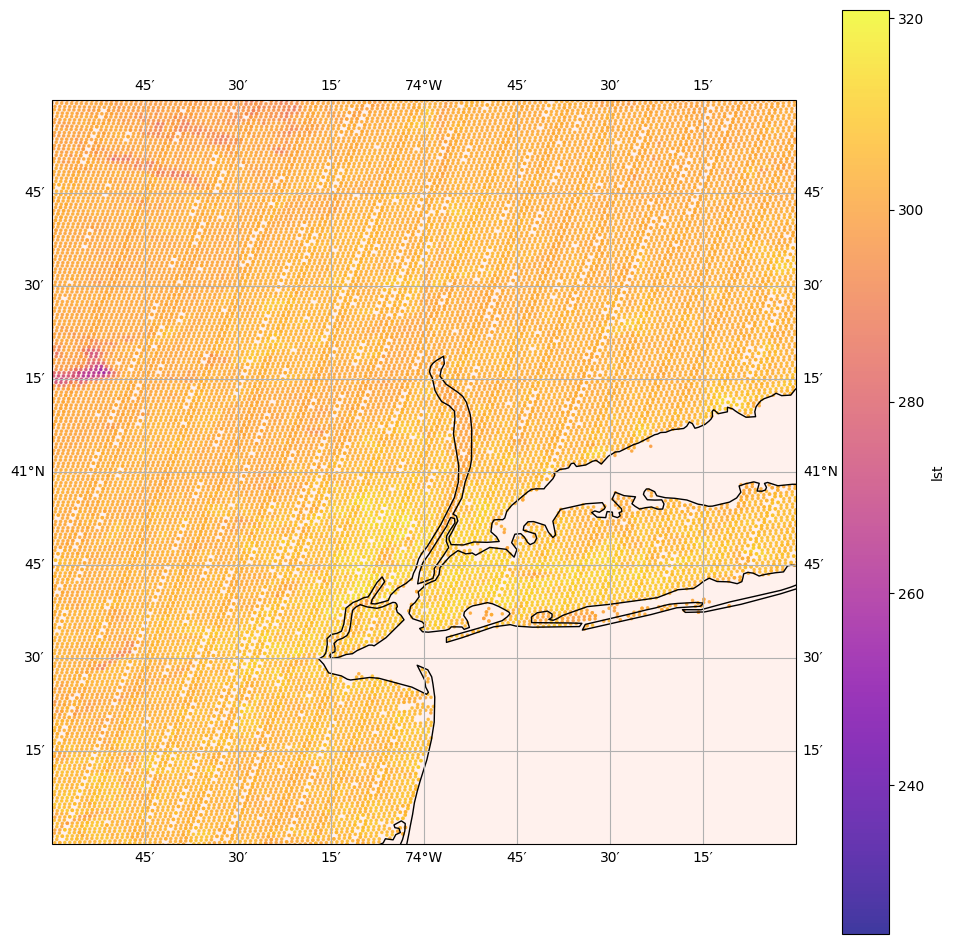

In [239]:
import shapely.geometry
from cartopy.crs import PlateCarree
from cartopy.feature import BORDERS
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 12), subplot_kw=dict(projection=PlateCarree()))
ax.set_facecolor('white')

ax.add_geometries(
    shapely.geometry.shape(item.geometry), crs=PlateCarree(), color="coral", alpha=0.1
)

scatter = data.plot.scatter(
    x="longitude",
    y="latitude",
    c="lst",  
    ax=ax,
    cmap="plasma",  
    marker=".",     
    alpha=0.8,      
    s=10,           # size of marker
)

lower_left = (40.75, -74.01)
upper_right = (40.88, -73.86)
ax.set_extent([lower_left[1], upper_right[1], lower_left[0], upper_right[0]], crs=PlateCarree())

ax.set(ybound=(40, 42), xbound=(-75, -73))
ax.coastlines()
ax.add_feature(BORDERS, linestyle="-")
ax.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False);

In [240]:
submission_file = pandas.read_csv("../data/Submission_template.csv")
submission_file

,Longitude,Latitude,UHI Index
0,-73.971665,40.788763,1
1,-73.971928,40.788875,1
2,-73.967080,40.789080,1
3,-73.972550,40.789082,1
4,-73.969697,40.787953,1
...,...,...,...
1035,-73.919388,40.813803,1
1036,-73.931033,40.833178,1
1037,-73.934647,40.854542,1
1038,-73.917223,40.815413,1


In [241]:
data

,longitude,latitude,lst
50,-87.829622,52.441963,286.462006
51,-87.829622,52.441963,286.462006
52,-87.809334,52.440007,285.954010
53,-87.799317,52.440464,285.936005
54,-87.779427,52.438736,285.779999
...,...,...,...
1799851,-74.454335,39.517924,303.563995
1799852,-74.441046,39.510563,304.290009
1799853,-74.426965,39.511543,302.660004
1799854,-74.412819,39.512522,306.609985


In [242]:
lower_left = (40.75, -74.01)
upper_right = (40.88, -73.86)

mask = (
    (data['longitude'] >= lower_left[1]) &  # longitude >= -74.01
    (data['longitude'] <= upper_right[1]) &  # longitude <= -73.86
    (data['latitude'] >= lower_left[0]) &    # latitude >= 40.75
    (data['latitude'] <= upper_right[0])     # latitude <= 40.88
)

filtered_data = data[mask]
print(filtered_data)

         longitude   latitude         lst
1564350 -73.921672  40.879170  304.391998
1564352 -73.899059  40.872004  311.914001
1564353 -73.884706  40.872927  312.097992
1564354 -73.870332  40.873843  311.686005
1565847 -73.950536  40.877471  309.309998
...            ...        ...         ...
1585353 -73.934017  40.751530  314.496002
1585354 -73.919695  40.752475  314.970001
1586847 -73.999366  40.756006  309.037994
1586848 -73.999366  40.756006  309.037994
1586849 -73.985328  40.756939  310.730011

[176 rows x 3 columns]


In [243]:
import numpy as np
from scipy.spatial import cKDTree

# Merging the file based on the closest
submission_coords = submission_file[['Longitude', 'Latitude']].values
data_coords = data[['longitude', 'latitude']].values
tree = cKDTree(data_coords)
distances, indices = tree.query(submission_coords, k=1)
closest_data = data.iloc[indices].reset_index(drop=True)
merged_df = submission_file.copy()
merged_df = merged_df.join(closest_data, rsuffix='_closest')

mean_temperature = merged_df['lst'].mean()
merged_df['UHI Index'] = merged_df['lst'] / mean_temperature
print(merged_df[['Longitude', 'Latitude', 'lst', 'UHI Index']])
print(submission_file.shape)
print(merged_df.shape)

      Longitude   Latitude         lst  UHI Index
0    -73.971665  40.788763  309.471985   0.993690
1    -73.971928  40.788875  309.471985   0.993690
2    -73.967080  40.789080  309.471985   0.993690
3    -73.972550  40.789082  309.471985   0.993690
4    -73.969697  40.787953  309.471985   0.993690
...         ...        ...         ...        ...
1035 -73.919388  40.813803  314.078003   1.008479
1036 -73.931033  40.833178  311.450012   1.000041
1037 -73.934647  40.854542  309.753998   0.994595
1038 -73.917223  40.815413  314.148010   1.008704
1039 -73.911645  40.804402  314.403992   1.009526

[1040 rows x 4 columns]
(1040, 3)
(1040, 6)


In [244]:
import numpy as np
from scipy.spatial import cKDTree

# Merging the file with the closest 3 measured data points
# k = 4
submission_coords = submission_file[['Longitude', 'Latitude']].values
data_coords = data[['longitude', 'latitude']].values

tree = cKDTree(data_coords)

distances, indices = tree.query(submission_coords, k=4)

closest_data_avg = data.iloc[indices.flatten()].groupby(np.repeat(np.arange(len(submission_coords)), 4)).mean()

merged_df = submission_file.copy()
merged_df = merged_df.join(closest_data_avg.reset_index(drop=True), rsuffix='_avg')

mean_temperature = merged_df['lst'].mean()
merged_df['UHI Index'] = merged_df['lst'] / mean_temperature
print(merged_df[['Longitude', 'Latitude', 'lst', 'UHI Index']])
print(submission_file.shape)
print(merged_df.shape)

      Longitude   Latitude         lst  UHI Index
0    -73.971665  40.788763  309.087006   0.993220
1    -73.971928  40.788875  309.087006   0.993220
2    -73.967080  40.789080  308.451996   0.991179
3    -73.972550  40.789082  309.087006   0.993220
4    -73.969697  40.787953  309.087006   0.993220
...         ...        ...         ...        ...
1035 -73.919388  40.813803  314.229004   1.009743
1036 -73.931033  40.833178  311.126495   0.999773
1037 -73.934647  40.854542  307.594513   0.988424
1038 -73.917223  40.815413  314.048004   1.009161
1039 -73.911645  40.804402  313.088013   1.006077

[1040 rows x 4 columns]
(1040, 3)
(1040, 6)



Transformed Values:
[0.98713481 0.98713481 0.98184573 ... 0.97787892 1.02117495 1.00925279]


C:\Users\16539\AppData\Local\Temp\ipykernel_10692\4054292779.py:28: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(training_data['UHI Index'], label='Training Data UHI Index', shade=True, color='blue')
c:\Users\16539\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\16539\AppData\Local\Temp\ipykernel_10692\4054292779.py:30: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(merged_df['UHI Index'], label='Merged Data UHI Index (Before Transformation)', shade=True, color='orange')
c:\Users\16539\AppData\Local\Progr

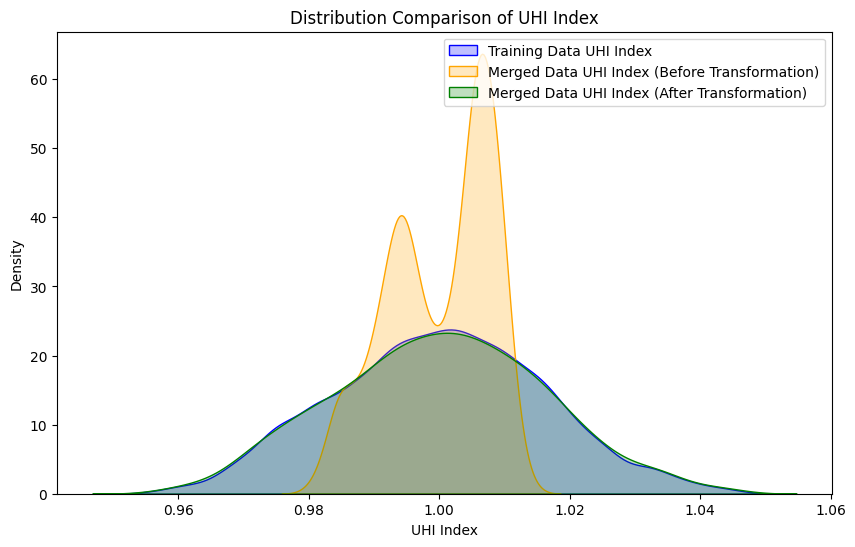

In [245]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import rankdata

file_path = r"C:\Users\16539\Documents\Aalto\25spring\EY2025\data\Training_data_uhi_index.csv"
training_data = pd.read_csv(file_path)

def quantile_matching(source, target):
    source_ranks = rankdata(source) / len(source)
    target_sorted = np.sort(target)

    transformed_values = np.interp(source_ranks, np.linspace(0, 1, len(target_sorted)), target_sorted)
    
    return transformed_values


transformed_values = quantile_matching(merged_df['UHI Index'], training_data['UHI Index'])
print("\nTransformed Values:")
print(transformed_values)

merged_df['UHI Index_transformed'] = transformed_values


plt.figure(figsize=(10, 6))

sns.kdeplot(training_data['UHI Index'], label='Training Data UHI Index', shade=True, color='blue')

sns.kdeplot(merged_df['UHI Index'], label='Merged Data UHI Index (Before Transformation)', shade=True, color='orange')

sns.kdeplot(merged_df['UHI Index_transformed'], label='Merged Data UHI Index (After Transformation)', shade=True, color='green')

plt.xlabel('UHI Index')
plt.ylabel('Density')
plt.title('Distribution Comparison of UHI Index')
plt.legend()

plt.show()

In [246]:
sub_file = merged_df.copy()
sub_file['UHI Index'] = sub_file['UHI Index_transformed']
sub_file[['Longitude', 'Latitude', 'UHI Index']].to_csv('submission.csv')

In [251]:
import pandas as pd
import planetary_computer
import pystac_client
import xarray as xr
import fsspec
from rich.table import Table
from IPython.display import display, Markdown

file_path = r"C:\Users\16539\Documents\Aalto\25spring\EY2025\data\Training_data_uhi_index_2025-02-18.csv"
training_data = pd.read_csv(file_path)

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

collection = catalog.get_collection("sentinel-3-slstr-lst-l2-netcdf")

bbox = [-74.01, 40.75, -73.86, 40.88]
time_window = "2021-06-01/2021-09-01"

search = catalog.search(
    bbox=bbox,
    datetime=time_window,
    collections=["sentinel-3-slstr-lst-l2-netcdf"],
    query={"eo:cloud_cover": {"lt": 30}},
)

items = list(search.get_items())

item = next(search.items())

t = Table("Key", "Value")
for key, asset in item.assets.items():
    t.add_row(key, asset.description)

dataset = xr.open_dataset(fsspec.open(item.assets["lst-in"].href).open())

geo = xr.open_dataset(fsspec.open(item.assets["slstr-geodetic-in"].href).open()).load()

lst_data = (
    pd.DataFrame(
        {
            "longitude": geo.longitude_in.data.ravel(),
            "latitude": geo.latitude_in.data.ravel(),
            "lst": dataset.LST.load().data.ravel(),
        }
    )
    .dropna()
)

submission_coords = training_data[['Longitude', 'Latitude']].values
data_coords = lst_data[['longitude', 'latitude']].values

tree = cKDTree(data_coords)

distances, indices = tree.query(submission_coords, k=4)

closest_data_avg = data.iloc[indices.flatten()].groupby(np.repeat(np.arange(len(submission_coords)), 4)).mean()

merged_df = training_data.copy()
merged_df = merged_df.join(closest_data_avg.reset_index(drop=True), rsuffix='_avg')
merged_df[['Longitude', 'Latitude', 'datetime','lst', 'UHI Index']].to_csv("training_data.csv", index=False)

mean_temperature = merged_df['lst'].mean()

merged_df['UHI_generated'] = merged_df['lst'] / mean_temperature
print(merged_df[['Longitude', 'Latitude', 'lst', 'UHI Index', 'UHI_generated']])
print(training_data.shape)
print(merged_df.shape)

C:\Users\16539\AppData\Roaming\Python\Python310\site-packages\pystac_client\item_search.py:826: FutureWarning: get_items() is deprecated, use items() instead
  warnings.warn(


       Longitude   Latitude         lst  UHI Index  UHI_generated
0     -73.909167  40.813107  314.112000   1.030289       1.009245
1     -73.909187  40.813045  314.112000   1.030289       1.009245
2     -73.909215  40.812978  314.112000   1.023798       1.009245
3     -73.909242  40.812908  314.112000   1.023798       1.009245
4     -73.909257  40.812845  314.112000   1.021634       1.009245
...          ...        ...         ...        ...            ...
11224 -73.957050  40.790333  309.700989   0.972470       0.995072
11225 -73.957063  40.790308  309.700989   0.972470       0.995072
11226 -73.957093  40.790270  309.700989   0.981124       0.995072
11227 -73.957112  40.790253  309.700989   0.981245       0.995072
11228 -73.957128  40.790237  309.700989   0.983408       0.995072

[11229 rows x 5 columns]
(11229, 4)
(11229, 8)


Mean Squared Error (MSE): 0.00023421600620046227
Mean Absolute Error (MAE): 0.012116899046966015
Correlation Coefficient (R): 0.35401137379980563
R-squared (R²): 0.111667442728005


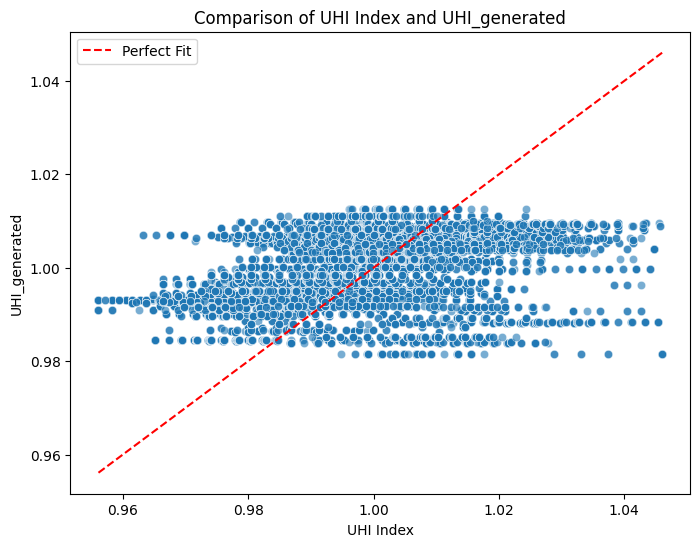

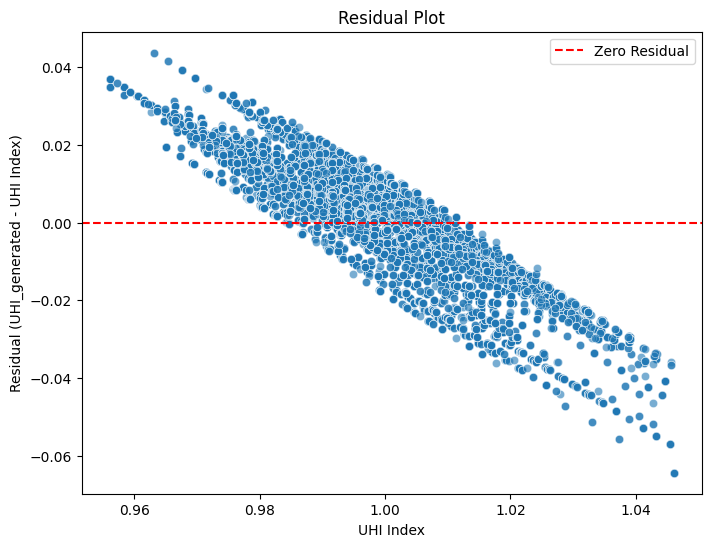

C:\Users\16539\AppData\Local\Temp\ipykernel_10692\4065008401.py:38: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(merged_data['UHI Index'], label='UHI Index', shade=True)
c:\Users\16539\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\16539\AppData\Local\Temp\ipykernel_10692\4065008401.py:39: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(merged_data['UHI_generated'], label='UHI_generated', shade=True)
c:\Users\16539\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\_oldcore.py:1119: FutureW

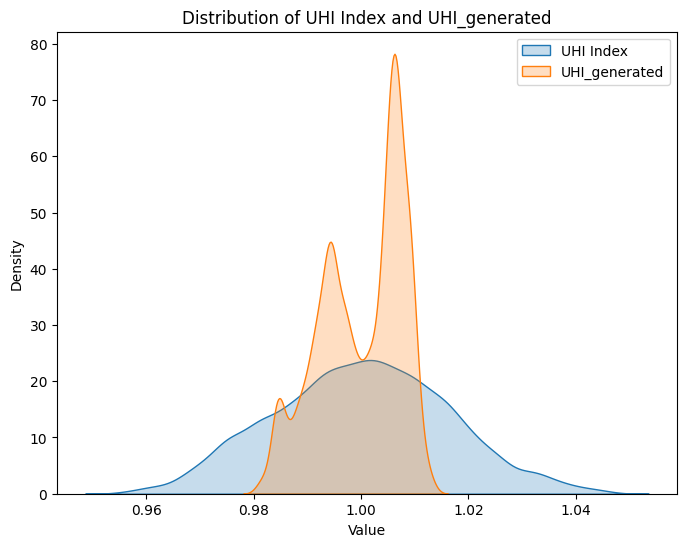

In [248]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
merged_data = merged_df
mse = mean_squared_error(merged_data['UHI Index'], merged_data['UHI_generated'])
mae = mean_absolute_error(merged_data['UHI Index'], merged_data['UHI_generated'])
r = merged_data['UHI Index'].corr(merged_data['UHI_generated'])
r2 = r2_score(merged_data['UHI Index'], merged_data['UHI_generated'])

print(f"Mean Squared Error (MSE): {mse}")
print(f"Mean Absolute Error (MAE): {mae}")
print(f"Correlation Coefficient (R): {r}")
print(f"R-squared (R²): {r2}")

plt.figure(figsize=(8, 6))
sns.scatterplot(x='UHI Index', y='UHI_generated', data=merged_data, alpha=0.6)
plt.plot([merged_data['UHI Index'].min(), merged_data['UHI Index'].max()],
         [merged_data['UHI Index'].min(), merged_data['UHI Index'].max()],
         color='red', linestyle='--', label='Perfect Fit')
plt.xlabel('UHI Index')
plt.ylabel('UHI_generated')
plt.title('Comparison of UHI Index and UHI_generated')
plt.legend()
plt.show()

merged_data['Residual'] = merged_data['UHI_generated'] - merged_data['UHI Index']
plt.figure(figsize=(8, 6))
sns.scatterplot(x='UHI Index', y='Residual', data=merged_data, alpha=0.6)
plt.axhline(y=0, color='red', linestyle='--', label='Zero Residual')
plt.xlabel('UHI Index')
plt.ylabel('Residual (UHI_generated - UHI Index)')
plt.title('Residual Plot')
plt.legend()
plt.show()

plt.figure(figsize=(8, 6))
sns.kdeplot(merged_data['UHI Index'], label='UHI Index', shade=True)
sns.kdeplot(merged_data['UHI_generated'], label='UHI_generated', shade=True)
plt.xlabel('Value')
plt.ylabel('Density')
plt.title('Distribution of UHI Index and UHI_generated')
plt.legend()
plt.show()

C:\Users\16539\AppData\Local\Temp\ipykernel_10692\3064606634.py:12: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(merged_data['UHI Index'], label='UHI Index', shade=True)
c:\Users\16539\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\16539\AppData\Local\Temp\ipykernel_10692\3064606634.py:13: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(merged_data['UHI_generated_transformed'], label='UHI_generated_transformed', shade=True)
c:\Users\16539\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\_

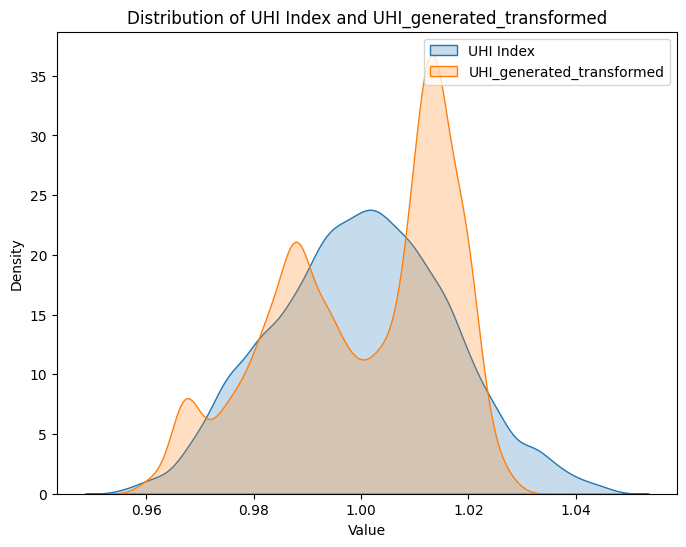

In [249]:

mean_uhi_index = merged_data['UHI Index'].mean()
std_uhi_index = merged_data['UHI Index'].std()
mean_uhi_generated = merged_data['UHI_generated'].mean()
std_uhi_generated = merged_data['UHI_generated'].std()

a = std_uhi_index / std_uhi_generated
b = mean_uhi_index - a * mean_uhi_generated

merged_data['UHI_generated_transformed'] = a * merged_data['UHI_generated'] + b

plt.figure(figsize=(8, 6))
sns.kdeplot(merged_data['UHI Index'], label='UHI Index', shade=True)
sns.kdeplot(merged_data['UHI_generated_transformed'], label='UHI_generated_transformed', shade=True)
plt.xlabel('Value')
plt.ylabel('Density')
plt.title('Distribution of UHI Index and UHI_generated_transformed')
plt.legend()
plt.show()

C:\Users\16539\AppData\Local\Temp\ipykernel_10692\2314327153.py:11: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(merged_data['UHI Index'], label='UHI Index', shade=True)
c:\Users\16539\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\16539\AppData\Local\Temp\ipykernel_10692\2314327153.py:12: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  sns.kdeplot(merged_data['UHI_generated_transformed'], label='UHI_generated_transformed', shade=True)
c:\Users\16539\AppData\Local\Programs\Python\Python310\lib\site-packages\seaborn\_

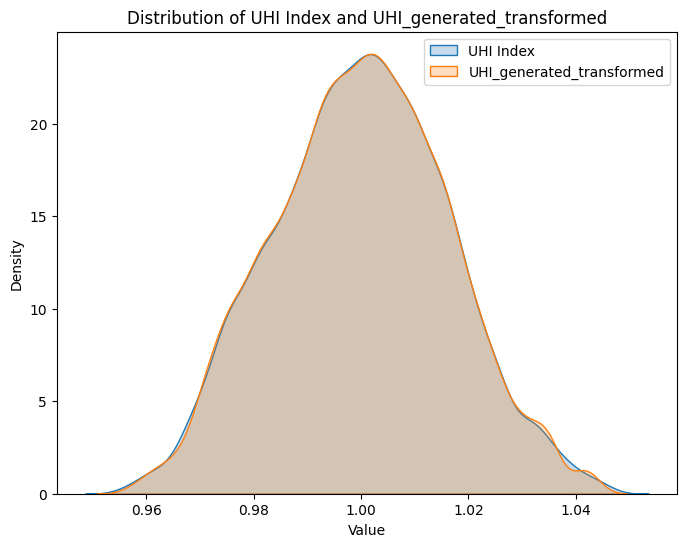

,Longitude,Latitude,datetime,UHI Index,longitude,latitude,lst,UHI_generated,Residual,UHI_generated_transformed
0,-73.909167,40.813107,24-07-2021 15:53,1.030289,-73.911638,40.812162,314.112,1.009245,-0.021044,1.023806
1,-73.909187,40.813045,24-07-2021 15:53,1.030289,-73.911638,40.812162,314.112,1.009245,-0.021044,1.023806
2,-73.909215,40.812978,24-07-2021 15:53,1.023798,-73.911638,40.812162,314.112,1.009245,-0.014553,1.023806
3,-73.909242,40.812908,24-07-2021 15:53,1.023798,-73.911638,40.812162,314.112,1.009245,-0.014553,1.023806
4,-73.909257,40.812845,24-07-2021 15:53,1.021634,-73.911638,40.812162,314.112,1.009245,-0.012389,1.023806


In [250]:
from scipy.stats import percentileofscore

def quantile_matching(source, target):
    return np.percentile(target, [percentileofscore(source, x) for x in source])

merged_data['UHI_generated_transformed'] = quantile_matching(
    merged_data['UHI_generated'], merged_data['UHI Index']
)

plt.figure(figsize=(8, 6))
sns.kdeplot(merged_data['UHI Index'], label='UHI Index', shade=True)
sns.kdeplot(merged_data['UHI_generated_transformed'], label='UHI_generated_transformed', shade=True)
plt.xlabel('Value')
plt.ylabel('Density')
plt.title('Distribution of UHI Index and UHI_generated_transformed')
plt.legend()
plt.show()

merged_data.head()